In [16]:
import proteosim as ps
proteins = ps.read_fasta("../data/sample_proteins.fasta")
len(proteins)

3

In [17]:
peptides = ps.digest_protein_collection(proteins, ps.enzyme_cleavage_patterns["Trypsin"])
sample_protein = proteins["P11802"]
sample_protein_peptides = peptides["P11802"]
sample_coverage = ps.compute_sequence_coverage(sample_protein, sample_protein_peptides)
sample_coverage

92.73927392739274

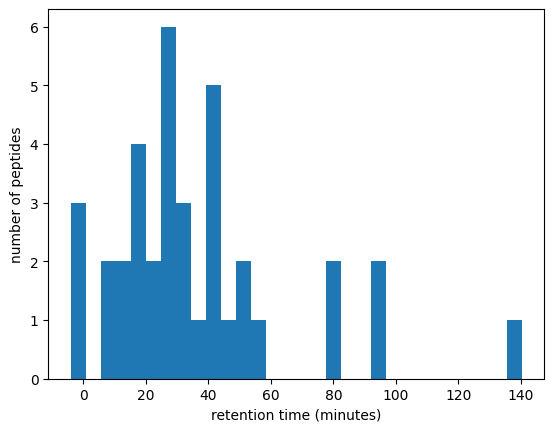

{'MATSR': 8.9,
 'TYLDK': 11.1,
 'DVSLPR': 14.7,
 'GAFPPR': 16.3,
 'ISAFR': 19.9,
 'SEEAVR': 5.7,
 'AYVQAR': 15.6,
 'VLESYR': 18.4}

In [18]:
pooled_peptides = sum(peptides.values(), [])
retention_times = ps.predict_lc_retention_times(pooled_peptides)

ps.plot_retention_time(retention_times)

selected_peptides = ps.select_retention_time_window(retention_times, lower_ret_time=0, upper_ret_time=20)
selected_peptides

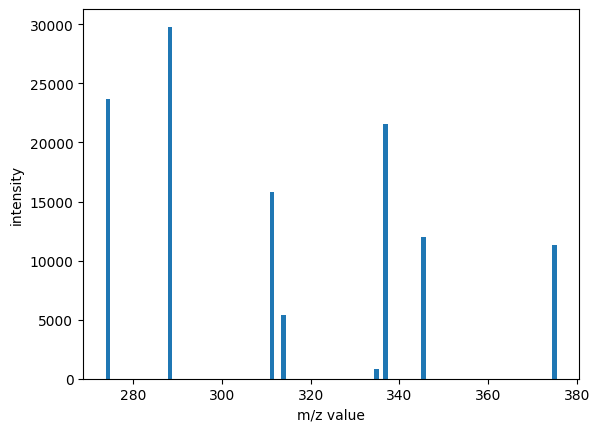

['M', 'MA', 'MAT', 'MATS', 'R', 'SR', 'TSR', 'ATSR']

In [19]:
mol_mass_collection = ps.calculate_mol_mass_collection(selected_peptides, ps.amino_acid_mass_dalton)
mz_collection = ps.calculate_mz_collection(mol_mass_collection, charge=2)

ps.plot_spectrum(mz_collection.values())

sample_peptide = "MATSR"
fragments = ps.fragment_peptide(sample_peptide)
fragments

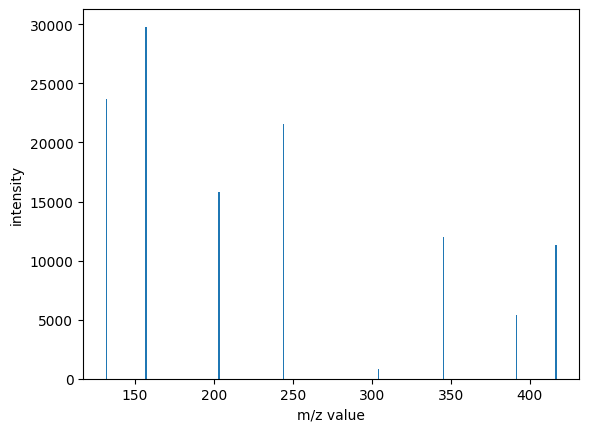

In [20]:
fragment_masses_ms2 = ps.calculate_mol_mass_collection(fragments, ps.amino_acid_mass_dalton)
fragment_mz2_collection = ps.calculate_mz_collection(fragment_masses_ms2, 1)

ps.plot_spectrum(fragment_mz2_collection.values())